In [2]:
import cupy as cp
from matplotlib import pyplot as plt
import os

def plot_density_unnormalized_int (grid, data, sum_axes=("z",), data_labels=("n"), title = "n", save_name=None, save_folder=None,units=None):
    if not isinstance(data,list):
        data = [data]
    sum_mapping = {"x": 1, "y": 0, "z": 2}
    sum_mapping_inv = {1: "x", 0: "y", 2: "z"}
    sum_ax_inds = tuple(sum_mapping[ax] for ax in sum_axes)
    data_int = []
    for d in data:
        data_int.append(cp.sum(d, axis=sum_ax_inds))
    grid_mapping = {"x":0, "y":1, "z":2}
    plot_axes = [sum_mapping_inv[ax_ind] for ax_ind in range(3) if sum_mapping_inv[ax_ind] not in sum_axes]
    plot_ax_inds = [grid_mapping[ax] for ax in plot_axes]
    fig, ax = plt.subplots()
    unit_factor = 1 if not units else units[0]
    unit_name = "lx" if not units else units[1]
    if len(plot_ax_inds) == 1:
        coords = cp.ravel(grid[plot_ax_inds[0]].get())
        for i,d in enumerate(data_int):
            ax.plot(coords*float(unit_factor),d,label=data_labels[i])
        ax.set_xlabel(plot_axes[0]+ "(" + unit_name + ")")
        ax.set_title(title)
        ax.legend()
        if save_name and save_folder:
            if not os.path.exists(save_folder):
                os.makedirs(save_folder)
            full_path = os.path.join(save_folder, save_name)
            fig.savefig(full_path)
    elif len(plot_ax_inds) == 2:
        coords_x = cp.ravel(grid[plot_ax_inds[0]].get())
        coords_y = cp.ravel(grid[plot_ax_inds[1]].get())
        for i,d in enumerate(data_int):
            ax.pcolormesh(coords_x*float(unit_factor), coords_y*float(unit_factor),d.T,label=data_labels[i])
        ax.set_xlabel(plot_axes[0]+ "(" + unit_name + ")")
        ax.set_ylabel(plot_axes[1]+ "(" + unit_name + ")")
        ax.set_title(title)
        ax.legend()
        if save_name and save_folder:
            if not os.path.exists(save_folder):
                os.makedirs(save_folder)
            full_path = os.path.join(save_folder, save_name)
            fig.savefig(full_path)
    else:
        raise ValueError("can only plot up to 2D")
    return fig

In [15]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import minimize_scalar
from cupy import fft as fftw
import cupy as cp
! pip install perlin_numpy
from perlin_numpy import generate_perlin_noise_3d

# functions
def run_simulation_ite(grid_shape, grid_boundaries, potential_fn, dt_input, iterations, guess, iter_check=100, tolerance=1e-4,use_tolerance=True, save_name=None, energy_fn=None, plot_all=True):
    grid,kgrid,psi = initialize_simulation(grid_shape, grid_boundaries, guess)
    errs = []
    mus = []
    psi_dev = []
    iters = []
    converged = False
    Es = []
    print("iterations:", iterations)
    max_iter=iterations-1
    for i in range(iterations):
        if i % iter_check == 0:
            if energy_fn:
                labels, E_components = energy_fn(psi, grid, kgrid)
                Es.append(E_components)
                Emax = max((E_components))
                dt = dt_input/cp.abs(Emax)
                dt = float(dt)
                print("dt:",dt)
            if plot_all:
                n_sim = cp.abs(psi)**2
                n_sim = n_sim.get()
                psi_fft = fftw.fftshift(fftw.fftn(psi))
                n_fft = cp.abs(psi_fft)**2
                n_fft = n_fft.get()
                Nx, Ny, Nz = grid_shape
                plot_density_unnormalized_int(grid,n_sim, sum_axes=("y",))
                plot_density_unnormalized_int(grid,n_sim, sum_axes=("z",))
                plt.show()
        psi_old = psi
        psi, psi_norm = imaginary_time_propagation_step(psi_old,grid,kgrid,potential_fn,dt)
        err = cp.sum(cp.abs(cp.abs(psi)-cp.abs(psi_old)))/(cp.sum(cp.abs(psi))*dt)
        errs.append(float(err.get()))
        # if cp.isnan(err):
        #     converged = False
        #     max_iter=i
        #     break
        mu_check = -1/2*cp.log(psi_norm)/dt
        if len(mus)>1: mu_dev = cp.abs((mu_check-mus[-2])/mu_check)
        if i % iter_check == 0:
            print("iteration: ", i)
            print(f"$\Delta \psi/\psi$ =", err.get())
        mus.append(float(mu_check.get()))
        if err.get() < tolerance and use_tolerance:
            converged = True
            print("converged!")
            max_iter = i
            break
        # if i>10 and err.get() > 0.1:
        #     max_iter=i
        #     converged=False
        #     break
    if energy_fn:
        print(Es)
        Es = cp.array(Es)
        for i, label in enumerate(labels):
            E_component = Es[:,i]
            E_component = E_component.get()
            plt.plot(E_component, label=label)
        plt.legend()
        if save_name:
          plt.savefig(save_name+"E.png")
    return grid, psi, max_iter, errs, mus, converged, Es

def run_simulation_rte(grid_shape, grid_boundaries, potential_fn, dt, iterations, guess):
    grid,kgrid,psi = initialize_simulation(grid_shape, grid_boundaries, guess)
    for i in range(iterations):
        psi, _ = real_time_propagation_step(psi,grid,kgrid,potential_fn,dt)
    return grid, psi

def initialize_simulation(grid_shape, grid_boundaries, guess, plot_guess=False):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    Nx, Ny, Nz = grid_shape
    kx = 2*cp.pi*cp.fft.fftfreq(Nx)*Nx/(xmax-xmin)
    ky =  2*cp.pi*cp.fft.fftfreq(Ny)*Ny/(ymax-ymin)
    kz =  2*cp.pi*cp.fft.fftfreq(Nz)*Nz/(zmax-zmin)
    grid = cp.meshgrid(x,y,z,sparse=True)
    kgrid = cp.meshgrid(kx,ky,kz,sparse=True)
    psi = guess
    if plot_guess:
        print("Guess:")
        plot_density_unnormalized_int(grid,(cp.abs(psi)**2).get())
        plt.show()
    print("simulation initialized")
    return (grid,kgrid,psi)

def imaginary_time_propagation_step(psi, grid, kgrid, potential, dt):
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    psi = kinetic_propagator(psi, grid, kgrid, dt/2)
    psi = cp.exp(-dt*potential(psi, grid, kgrid))*psi
    psi = kinetic_propagator(psi, grid, kgrid, dt/2)
    psi_norm = cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)
    while cp.isinf(psi_norm):
      psi = psi/10**10
      psi_norm =  cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)
    return psi/cp.sqrt(psi_norm), psi_norm

def real_time_propagation_step(psi, grid, kgrid, potential_propagator, dt):
    return imaginary_time_propagation_step(psi, grid, kgrid, potential_propagator, 1j*dt)

def harmonic_potential(psi,grid,kgrid,gamma,anisotropy):
    x, y, z = grid
    return 1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)+gamma*cp.abs(psi)**2

def dipolar_potential(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction):
    x, y, z = grid
    harmonic_plus_contact = 1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)+gamma*cp.abs(psi)**2
    # dipolar term
    fft_n = fftw.fftn(cp.abs(psi)**2)
    kx, ky, kz = kgrid
    kabs = cp.sqrt(kx**2+ky**2+kz**2)
    costheta = (kx*dipole_direction[0]+ky*dipole_direction[1]+kz*dipole_direction[2])/kabs
    dipole_fft = dipole_strength*(3*costheta**2-1)
    dipole_fft[kabs==0] = 0
    dipolar = fftw.ifftn(dipole_fft*fft_n)
    return dipolar+harmonic_plus_contact

def dipolar_potential_LHY(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction,LHY_strength):
    x, y, z = grid
    harmonic_plus_contact = 1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)+gamma*cp.abs(psi)**2
    # dipolar term
    fft_n = fftw.fftn(cp.abs(psi)**2)
    kx, ky, kz = kgrid
    kabs = cp.sqrt(kx**2+ky**2+kz**2)
    costheta = (kx*dipole_direction[0]+ky*dipole_direction[1]+kz*dipole_direction[2])/kabs
    dipole_fft = dipole_strength*(3*costheta**2-1)
    dipole_fft[kabs==0] = 0
    dipolar = fftw.ifftn(dipole_fft*fft_n)
    LHY = LHY_strength*cp.abs(psi)**3
    return dipolar+harmonic_plus_contact+LHY

def dipolar_potential_LHY_cutoff(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction,LHY_strength,cutoff_radius=None):
    x, y, z = grid
    if not cutoff_radius:
      cutoff_radius = cp.max(cp.array([cp.max(x), cp.max(y), cp.max(z)]))
    harmonic_plus_contact = 1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)+gamma*cp.abs(psi)**2
    # dipolar term
    fft_n = fftw.fftn(cp.abs(psi)**2)
    kx, ky, kz = kgrid
    kabs = cp.sqrt(kx**2+ky**2+kz**2)
    costheta = (kx*dipole_direction[0]+ky*dipole_direction[1]+kz*dipole_direction[2])/kabs
    dipole_fft = (1+3*cp.cos(cutoff_radius*kabs)/(cutoff_radius*kabs)**2-3*cp.sin(cutoff_radius*kabs)/(cutoff_radius*kabs)**3)*dipole_strength*(3*costheta**2-1)
    dipole_fft[kabs==0] = 0
    dipolar = fftw.ifftn(dipole_fft*fft_n)
    LHY = LHY_strength*cp.abs(psi)**3
    return dipolar+harmonic_plus_contact+LHY

def cylindrical_dipolar_potential(psi,grid,kgrid,gamma,trap_ratio,dipole_strength):
    x, y, z = grid
    # harmonic potential
    harmonic_plus_contact = 1/2*(x**2+y**2+trap_ratio**2*z**2)+gamma*cp.abs(psi)**2
    # dipolar potential
    fft_n = fftw.fftn(cp.abs(psi)**2)
    kx, ky, kz = kgrid
    kabs = cp.sqrt(kx**2+ky**2+kz**2)
    costheta = (kz)/kabs
    costheta = cp.nan_to_num(costheta)
    dipole_fft = dipole_strength*(3*costheta**2-1)
    dipole_fft[kabs==0] = 0
    dipolar = fftw.ifftn(dipole_fft*fft_n)
    return dipolar+harmonic_plus_contact


def kinetic_propagator(psi, grid, kgrid, dt):
    fft_psi = cp.fft.fftn(psi)
    kx, ky, kz = kgrid
    ksquared = kx**2+ky**2+kz**2
    return cp.fft.ifftn(cp.exp(-1/2*ksquared*dt)*fft_psi)


def Gaussian_ansatz(grid_shape, grid_boundaries, sigmax, sigmay, sigmaz, noise_level):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    grid = cp.meshgrid(x,y,z,sparse=True)
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    rng = cp.random.default_rng()
    psi = cp.exp(-2*((x**2)/(sigmax**2)+y**2/sigmay**2 + z**2/sigmaz**2))
    noise = -1+2*(rng.random(cp.shape(psi)))
    psi = psi + psi*noise*noise_level
    random_phase = 2*cp.pi*1j*noise_level*(rng.random(cp.shape(psi)))
    psi = psi*cp.exp(random_phase)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    psi_norm = cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)
    return psi/cp.sqrt(psi_norm)

def Gaussian_ansatz_cyl(grid_shape, grid_boundaries, sigmar, sigmaz, noise_level=0):
    xmin, xmax, ymin, ymax, zmin, zmax = cp.ravel(grid_boundaries)
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    grid = cp.meshgrid(x,y,z,sparse=True)
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    rng = cp.random.default_rng()
    psi = cp.exp(-2*((x**2+y**2)/(sigmar**2) + z**2/sigmaz**2))
    noise = -1+2*(rng.random(cp.shape(psi)))
    psi = psi + psi*noise*noise_level
    random_phase = 2*cp.pi*1j*noise_level*(rng.random(cp.shape(psi)))
    psi = psi*cp.exp(random_phase)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    psi_norm = cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)
    return psi/cp.sqrt(psi_norm)

def random_guess(grid_shape, grid_boundaries):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    grid = cp.meshgrid(x,y,z,sparse=True)
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    rng = cp.random.default_rng()
    psi = rng.random(cp.shape(x+y+z))*cp.exp(2j*cp.pi*rng.random(cp.shape(x+y+z)))
    # psi = gaussian_filter(psi, 1)
    psi = (fftw.fftn(cp.array(psi)))
    psi_norm = cp.array(cp.sqrt(cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)))
    return psi/psi_norm

def perlin_guess(grid_shape, grid_boundaries, res=(2,2,2)):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    grid = cp.meshgrid(x,y,z,sparse=True)
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    psi = cp.array(generate_perlin_noise_3d(cp.shape(x+y+z), res))
    # psi = gaussian_filter(psi, 1)
    psi_norm = cp.sqrt(cp.sum(cp.abs(psi)**2*dLx*dLy*dLz))
    return psi/psi_norm

def Gaussian_ansatz_TF(grid_shape, grid_boundaries, gamma,anisotropy):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    grid = cp.meshgrid(x,y,z,sparse=True)
    x, y, z = grid
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    mu = (15*gamma/(8*2**(3/2)*cp.pi)*cp.sqrt(anisotropy[0]*anisotropy[1]*anisotropy[2]))**(2/5)
    Rx, Ry, Rz = cp.sqrt(2*mu/anisotropy[0]), cp.sqrt(2*mu/anisotropy[1]), cp.sqrt(2*mu/anisotropy[2])
    psi = cp.exp(-2*(x**2/Rx**2+y**2/Ry**2+z**2/Rz**2))
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    psi_norm = cp.sum(cp.abs(psi)**2*dLx*dLy*dLz)
    return psi/cp.sqrt(psi_norm)



def thomas_fermi_density(grid_shape, grid_boundaries, gamma,anisotropy):
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    Nx, Ny, Nz = grid_shape
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y),  cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    x,y,z = cp.meshgrid(x,y,z,sparse=True)
    potential = 1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)
    mu = (15*gamma/(8*2**(3/2)*cp.pi)*cp.sqrt(anisotropy[0]*anisotropy[1]*anisotropy[2]))**(2/5)
    tf = (mu-potential)/gamma
    tf[tf<0] = 0
    tf_norm = cp.sum(tf*dLx*dLy*dLz)
    return tf/tf_norm

def thomas_fermi_cyl_dipole (grid_shape, grid_boundaries, epsdd, gamma,trap_ratio,return_mu=False,return_R=False):
    def fdip(kappa):
        if kappa**2 == 1:
            return 0
        if kappa**2 > 1:
            return (1+2*kappa**2)/(1-kappa**2)+3*kappa**2*cp.atan(cp.sqrt(kappa**2-1))/(kappa**2-1)**(3/2)
        return (1+2*kappa**2)/(1-kappa**2)-3*kappa**2*cp.atanh(cp.sqrt(1-kappa**2))/(1-kappa**2)**(3/2)
    def aspect_ratio(edd, trap_ratio):
        fn = lambda kappa: cp.asnumpy(3*kappa**2*edd*((trap_ratio**2/2+1)*fdip(kappa)/(1-kappa**2)-1)+(edd-1)*(kappa**2-trap_ratio**2))
        fn2 = lambda kappa: cp.asnumpy(fn(kappa)**2)
        sol = minimize_scalar(fn2,bracket=(0.1,2),bounds=(0,50),method="bounded",tol=1e-9)
        return sol.x
    # calculate TF radii
    kappa = aspect_ratio(float(epsdd), float(trap_ratio))
    if kappa == 1:
        R_rho = (15/(4*cp.pi)*kappa*gamma*(1+epsdd*(3/2*kappa**2*(-2/5) - 1)))**(1/5)
    else:
        R_rho = (15/(4*cp.pi)*kappa*gamma*(1+epsdd*(3/2*kappa**2*fdip(kappa)/(1-kappa**2) - 1)))**(1/5)
    R_z = R_rho/kappa
    # calculate density profile
    xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
    x = cp.linspace(xmin,xmax,num=grid_shape[0])
    y =  cp.linspace(ymin,ymax,num=grid_shape[1])
    z =  cp.linspace(zmin,zmax,num=grid_shape[2])
    Nx, Ny, Nz = grid_shape
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y),  cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
    x,y,z = cp.meshgrid(x,y,z,sparse=True)
    tf = (1-(x**2+y**2)/R_rho**2-z**2/R_z**2)
    tf[tf<0] = 0
    tf_norm = cp.sum(tf*dLx*dLy*dLz)
    if return_mu:
        mu = 15/(8*cp.pi*R_rho**2*R_z)*gamma*(1-epsdd*fdip(kappa))
        return mu
    if return_R:
        return R_rho, R_z
    return tf/tf_norm

def energy_functional_dipole_LHY_cutoff(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction,LHY_strength):
    print(type(psi))
    fft_psi = fftw.fftn(psi)
    fft_n = fftw.fftn(cp.abs(psi)**2)
    kx, ky, kz = kgrid
    x, y, z = grid
    cutoff_radius = cp.max(cp.array([cp.max(x), cp.max(y), cp.max(z)]))
    Nx, Ny, Nz = cp.size(x), cp.size(y), cp.size(z)
    Lx, Ly, Lz = cp.max(x)-cp.min(x), cp.max(y)-cp.min(y), cp.max(z)-cp.min(z)
    dLx, dLy, dLz = Lx/Nx, Ly/Ny, Lz/Nz
    kabs = cp.sqrt(kx**2+ky**2+kz**2)
    costheta = (kx*dipole_direction[0]+ky*dipole_direction[1]+kz*dipole_direction[2])/kabs
    costheta = cp.nan_to_num(costheta)
    dipole_fft = (1+3*cp.cos(cutoff_radius*kabs)/(cutoff_radius*kabs)**2-3*cp.sin(cutoff_radius*kabs)/(cutoff_radius*kabs)**3)*dipole_strength*(3*costheta**2-1)
    dipole_fft[kabs==0] = 0
    KE = (cp.sum(cp.conj(psi)*fftw.ifftn(kabs**2/2*fft_psi)*dLx*dLy*dLz))
    harmonic = (cp.sum(1/2*(anisotropy[0]*x**2+anisotropy[1]*y**2+anisotropy[2]*z**2)*cp.abs(psi)**2*dLx*dLy*dLz))
    contact = (cp.sum(1/2*gamma*cp.abs(psi)**4*dLx*dLy*dLz))
    LHY = (cp.sum(2/5*LHY_strength*cp.abs(psi)**5*dLx*dLy*dLz))
    dipolar = (cp.sum(1/2*fftw.ifftn(dipole_fft*fft_n)*cp.abs(psi)**2*dLx*dLy*dLz))
    E = float(cp.real(KE+harmonic+contact+LHY+dipolar))
    print("KE: ", KE)
    print("harmonic: ", harmonic)
    print("contact: ", contact)
    print("dipolar: ", dipolar)
    print("LHY: ", LHY)
    print("E: ", E)
    labels = ("KE", "harmonic", "contact", "dipolar", "LHY", "E")
    energies = (float(cp.real(KE)), float(harmonic), float(contact), float(cp.real(dipolar)), float(LHY), E)
    return labels, energies



<>:51: SyntaxWarning: invalid escape sequence '\D'
<>:51: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_218/791597066.py:51: SyntaxWarning: invalid escape sequence '\D'
  print(f"$\Delta \psi/\psi$ =", err.get())


1.031476171135978e-06
<class 'cupy.ndarray'>
simulation initialized
iterations: 10000
<class 'cupy.ndarray'>
KE:  (14.096539340813434+3.209238430557093e-17j)
harmonic:  119.31463254268829
contact:  0.6165978406145171
dipolar:  (-0.1858679252264503-2.659170247694426e-18j)
LHY:  0.009110247811280588
E:  133.85101204670104
dt: 0.0007470993193918451
iteration:  0
$\Delta \psi/\psi$ = 99.03192693540633
<class 'cupy.ndarray'>
KE:  (0.3951090522790751-5.421010862427522e-19j)
harmonic:  14.231878616013747
contact:  3.4677806958907746
dipolar:  (3.6972859527974116+8.51100326982759e-18j)
LHY:  0.11694930723260907
E:  21.909003624213618
dt: 0.00456433353680589
iteration:  100
$\Delta \psi/\psi$ = 3.407665378624775
<class 'cupy.ndarray'>
KE:  (0.5322141307310934+1.5043305143236374e-18j)
harmonic:  12.962391699587617
contact:  3.7839514701351553
dipolar:  (4.18442773008382+1.4685810273607968e-17j)
LHY:  0.12922116771198916
E:  21.592206198249677
dt: 0.004631300714797095
iteration:  200
$\Delta \psi

/tmp/ipykernel_218/791597066.py:300: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  sol = minimize_scalar(fn2,bracket=(0.1,2),bounds=(0,50),method="bounded",tol=1e-9)
/tmp/ipykernel_218/2374223046.py:40: UserWarning: Legend does not support handles for QuadMesh instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
/tmp/ipykernel_218/2374223046.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


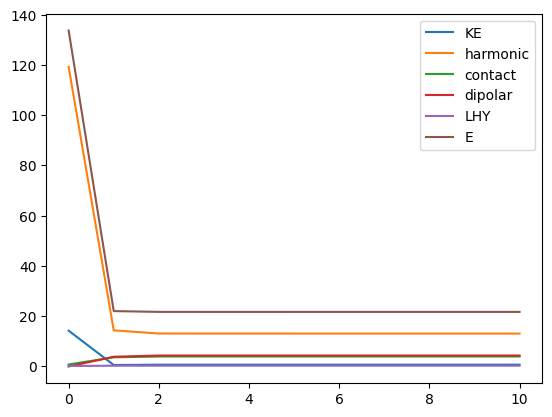

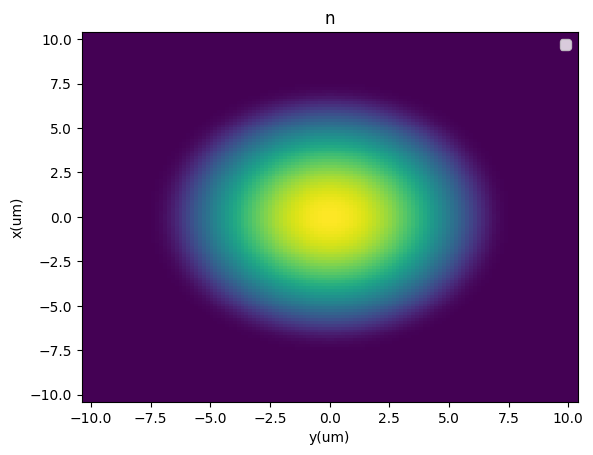

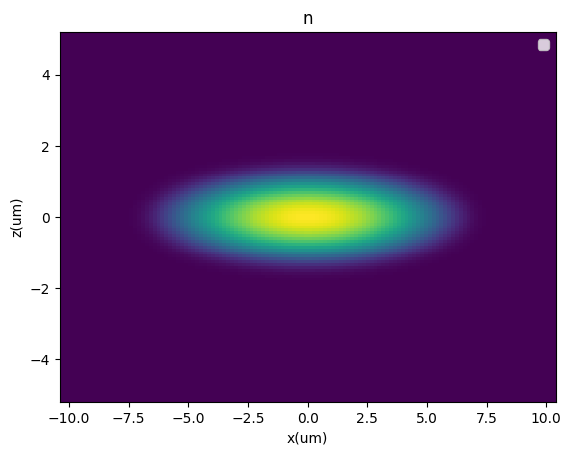

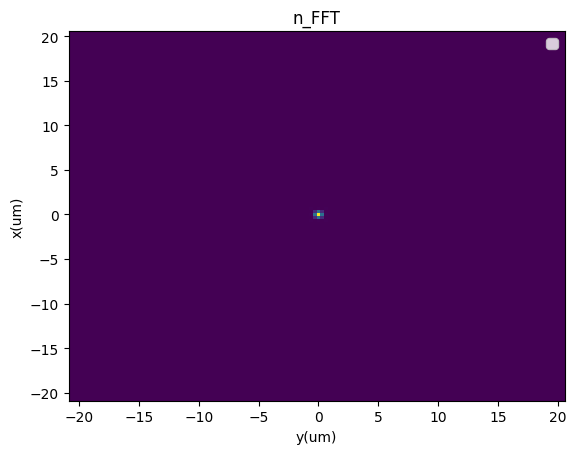

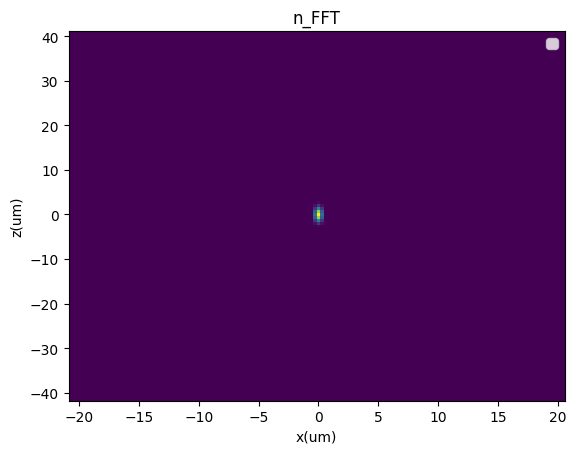

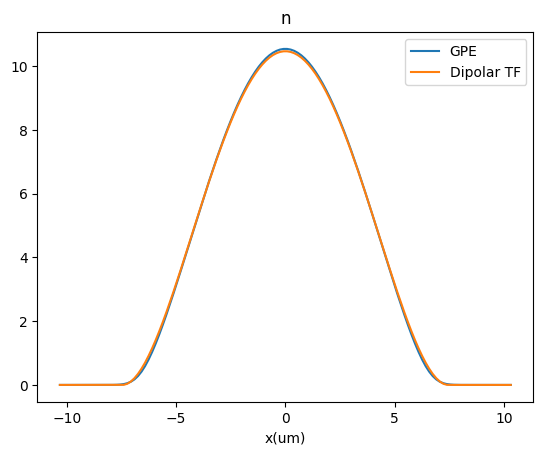

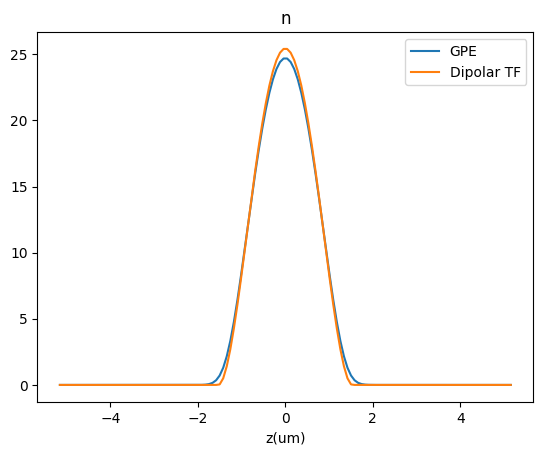

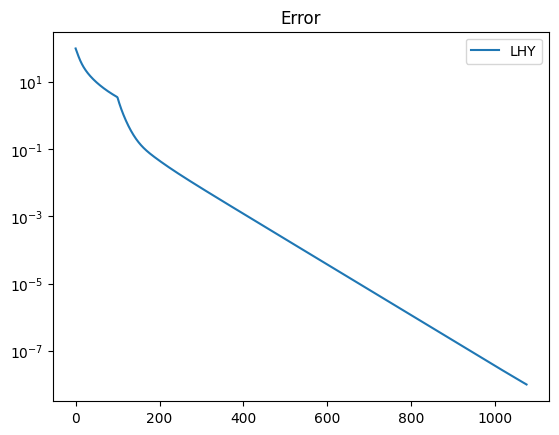

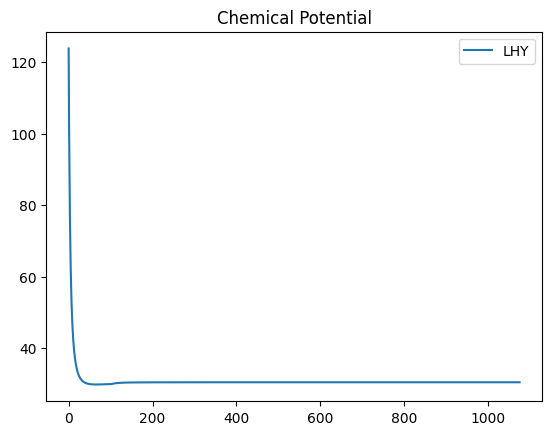

In [16]:
import cupy as cp
import sys
import csv

# physical constants
hbar = 1.05e-34 # J.s
a0 = 5.29e-11 # m

# experimental parameters
wx = 2*cp.pi*57
wy = 2*cp.pi*57
wz = 2*cp.pi*334
trap_ratio = wz/wx
add = 66*a0
ascat = 70*a0
Natoms = 40000
m = 166*1.66e-27
g = 4*cp.pi*hbar**2*ascat/m
epsdd = add/ascat
gdd = 4*cp.pi*hbar**2*add/m
Q5edd = 1+3*epsdd**2/2

gLHY = (32/(3*cp.sqrt(cp.pi)))*g*ascat**(3/2)*Q5edd

# dimensionless units
l = cp.sqrt(hbar/(m*wx))
tau = 1/wx

print(l)

gamma = Natoms*g/(hbar*wx*l**3)
dipole_strength = gdd*Natoms/(hbar*wx*l**3)
LHY_strength = gLHY*Natoms**(3/2)/(hbar*wx*l**(9/2))
anisotropy = [1, (wy/wx)**2, (wz/wx)**2]
dipole_direction = [0, 0, 1]

# simulation parameters
Nx = 2**7
Ny = 2**7
Nz = 2**7
grid_shape = [Nx, Ny, Nz]
iterations = 10000
tolerance = 1e-8
time_step = 1e-1
Lx = 20
Ly = 20
Lz = 10
grid_boundaries = [-Lx/2, Lx/2, -Ly/2, Ly/2, -Lz/2, Lz/2]

potential_fn = lambda psi, grid, kgrid: dipolar_potential_LHY_cutoff(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction,LHY_strength)
energy_fn = lambda psi, grid, kgrid: energy_functional_dipole_LHY_cutoff(psi,grid,kgrid,gamma,anisotropy,dipole_strength,dipole_direction,LHY_strength)
# guess = perlin_guess(grid_shape, grid_boundaries, (8,8,8))
# guess = random_guess(grid_shape, grid_boundaries)
guess = Gaussian_ansatz(grid_shape, grid_boundaries, 10, 10, 10, 0.1)
print(type(guess))
save_folder = None
# save_name = save_folder+"/Er"
grid, psi, max_iter_LHY, errs, mus, converged, Es = run_simulation_ite(grid_shape,grid_boundaries,potential_fn,time_step,iterations,guess,tolerance=tolerance,iter_check=100, energy_fn=energy_fn, plot_all=False)
print("converged:", converged)
print("energy:", cp.real(Es[-1][-1]))
psi_fft = fftw.fftshift(fftw.fftn(psi))
xmin, xmax, ymin, ymax, zmin, zmax = grid_boundaries
kx = 2*cp.pi*fftw.fftshift(fftw.fftfreq(Nx)*Nx/(xmax-xmin))
ky =  2*cp.pi*fftw.fftshift(fftw.fftfreq(Ny)*Ny/(ymax-ymin))
kz =  2*cp.pi*fftw.fftshift(fftw.fftfreq(Nz)*Nz/(zmax-zmin))
kgrid = cp.meshgrid(kx,ky,kz,sparse=True)

# plot result
n_sim = cp.abs(psi)**2
n_sim = n_sim.get()
nfft = cp.abs(psi_fft)**2
nfft = nfft.get()
nTF = thomas_fermi_cyl_dipole (grid_shape, grid_boundaries, epsdd, gamma,trap_ratio)
nTF = nTF.get()
plot_density_unnormalized_int(grid,n_sim, sum_axes=("z",), save_name="0_xy_density.png", save_folder=save_folder, data_labels=("n",), units=(l*1e6, "um"))
plot_density_unnormalized_int(grid,n_sim,sum_axes=("y",), save_name="0_xz_density.png", save_folder=save_folder, data_labels=("n",), units=(l*1e6, "um"))
plot_density_unnormalized_int(kgrid, nfft, sum_axes=("z",), data_labels=("n_FFT",), title="n_FFT", units=(l*1e6, "um"))
plot_density_unnormalized_int(kgrid, nfft, sum_axes=("y",), data_labels=("n_FFT",), title="n_FFT", units=(l*1e6, "um"))


plot_density_unnormalized_int(grid,[n_sim,nTF],sum_axes=("y","z"), data_labels=("GPE","Dipolar TF"), save_name="x_density.png", save_folder=save_folder, units=(l*1e6, "um"))
plot_density_unnormalized_int(grid,[n_sim,nTF],sum_axes=("x","y"), data_labels=("GPE","Dipolar TF"), save_name="z_density.png", save_folder=save_folder, units=(l*1e6, "um"))
plt.show()

# plot convergence
iters_LHY = cp.arange(0,max_iter_LHY+1,1)
plt.plot(iters_LHY.get(), errs, label="LHY")
plt.title("Error")
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(iters_LHY.get(), mus, label="LHY")
plt.title("Chemical Potential")
plt.legend()
plt.show()

39999.99999999999
39999.999999999905


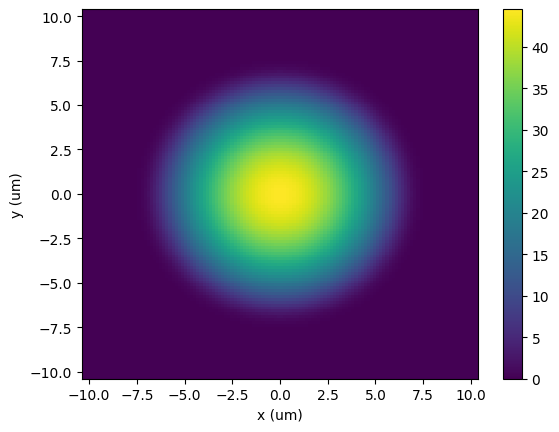

In [22]:
cross_section_er = float(3*(401e-9)**2/(2*np.pi))
x, y, z = grid
x = x*l
y = y*l
z = z*l
x = x.ravel()
y = y.ravel()
z = z.ravel()
dLx, dLy, dLz = Lx/(Nx-1), Ly/(Ny-1), Lz/(Nz-1)
n_xy = np.sum(n_sim*dLz,axis=2)*Natoms/float(l)**2
dx = x[1]-x[0]
dy = y[1]-y[0]
dz = z[1]-z[0]
print(np.sum(n_sim*dLx*dLy*dLz)*Natoms)
print(np.sum(n_xy*float(dx)*float(dy)))
OD_xy = n_xy*cross_section_er

plt.pcolormesh(1e6*x.get(), 1e6*y.get(), OD_xy)
plt.xlabel("x (um)")
plt.ylabel("y (um)")
plt.colorbar()